# Confidence-Aware Self-Prompting for Robust Polyp Segmentation Under Image and Domain Shifts

**Phase 3: Implementation & Execution** · Group **F26-13** · AI2002 Artificial Intelligence (BDS-5A), FAST-NUCES Lahore, Fall 2026 · Track A (R&D) · Instructor: Dr. Hajra Waheed

| Name | Roll number |
|---|---|
| Kashish Fatima (lead) | 24L-2605 |
| Khushbakht Sohail | 24L-2604 |
| Zahra Saeed | 24L-2512 |

Repository: https://github.com/kashishfatima999/Confidence-Aware-Self-Prompting-for-Robust-Polyp-Segmentation

This notebook is the complete Phase 3 run on Google Colab (T4 GPU) and contains the outputs of that run. It clones the repository, installs the model packages, prepares the data, trains (or reloads) the YOLOv8-m detector, builds the detection cache, runs the validation grid for CASP, runs the six experiments on both test sets and the nine corrupted settings, and builds the results tables. Section 10 shows the tables and figures used in the report. To reproduce: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Finished runs are saved to Google Drive and skipped on a re-run, so a dropped session only costs the run in progress.

| Notebook section | Report section |
|---|---|
| 1–3 GPU, code, packages, weights | §2 Implementation details |
| 4 Data | §4 Training process (data split) |
| 5 Train the detector | §4 Training process |
| 6 Detection cache | §3 Code workflow |
| 7 Validation grid | §4 Choosing CASP's thresholds |
| 8–9 Experiments and tables | §5 Initial results |
| 10 Results used in the report | §5, Figures 1–2 |

## 1. GPU, Drive, code

In [1]:
!nvidia-smi

Fri Oct 16 20:23:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!rm -rf /content/proj
!git clone https://github.com/kashishfatima999/Confidence-Aware-Self-Prompting-for-Robust-Polyp-Segmentation.git /content/proj
%cd /content/proj
!git log -1 --format="Our commit: %h %s"
!git clone -q https://github.com/sajjad-sh33/YOLO_SAM2.git external/YOLO_SAM2

Mounted at /content/drive
Cloning into '/content/proj'...
remote: Enumerating objects: 273, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 273 (delta 15), reused 40 (delta 10), pack-reused 217 (from 1)
Receiving objects: 100% (273/273), 12.04 MiB | 16.56 MiB/s, done.
Resolving deltas: 100% (96/96), done.
/content/proj
Our commit: 2b9c761 Merge pull request #9 from kashishfatima999/kashish-phase3


## 2. Packages (DL-26: Colab's own numpy/Pillow/OpenCV; only the model packages are installed) and tests

In [3]:
!pip install -q -r requirements-colab.txt
!SAM2_BUILD_CUDA=0 pip install -q "git+https://github.com/facebookresearch/sam2.git@2b90b9f5ceec907a1c18123530e92e794ad901a4"
!pip freeze | grep -i -E "^torch==|^ultralytics==|^numpy==|^pillow==|SAM-2"
!python -m unittest discover -s tests 2>&1 | tail -3

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 6.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 13.5 MB/s eta 0:00:00
numpy==2.1.3
pillow==11.3.0
SAM-2 @ git+https://github.com/facebookresearch/sam2.git@2b90b9f5ceec907a1c18123530e92e794ad901a4
torch==2.11.0+cu130
ultralytics==8.4.174
Ran 65 tests in 5.891s

OK


## 3. Weights (Drive, downloaded once)

In [4]:
import os, shutil
W = "/content/drive/MyDrive/F26-13/weights"
os.makedirs(W, exist_ok=True); os.makedirs("weights", exist_ok=True)
!wget -q -nc -P {W} https://dl.fbaipublicfiles.com/segment_anything_2/072824/sam2_hiera_large.pt
!cd {W} && python -c "from ultralytics import YOLO; YOLO('yolov8m.pt')"
!ln -sf {W}/sam2_hiera_large.pt weights/sam2_hiera_large.pt
!ls -la {W}

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
total 927830
drwx------ 2 root root      4096 Oct 11 15:54 .
drwx------ 9 root root      4096 Oct 11 15:54 ..
-rw------- 1 root root 897952466 Jul 28  2024 sam2_hiera_large.pt
-rw------- 1 root root  52136884 Oct 11 15:55 yolov8m.pt


## 4. Data (same as Phase 2: Kaggle copies, our prepare scripts, committed split)

In [5]:
import os, glob, json, shutil
import kagglehub
import pandas as pd
from PIL import Image
os.chdir("/content/proj")

p = kagglehub.dataset_download("debeshjha1/kvasirseg")
src = f"{p}/Kvasir-SEG/Kvasir-SEG"
dest = "data/raw/kvasir-seg/Kvasir-SEG"

shutil.rmtree(dest, ignore_errors=True)
shutil.copytree(f"{src}/images", f"{dest}/images")   # copy, never move
shutil.copytree(f"{src}/masks", f"{dest}/masks")

boxes = {}
for csv_path in sorted(glob.glob(f"{src}/bbox/*.csv")):
    image_id = os.path.splitext(os.path.basename(csv_path))[0]
    df = pd.read_csv(csv_path)
    df.columns = [c.strip().lower() for c in df.columns]
    w, h = Image.open(f"{dest}/images/{image_id}.jpg").size
    boxes[image_id] = {"height": h, "width": w,
                       "bbox": [{"label": "polyp", "xmin": int(r["xmin"]), "ymin": int(r["ymin"]),
                                 "xmax": int(r["xmax"]), "ymax": int(r["ymax"])} for _, r in df.iterrows()]}
with open(f"{dest}/kavsir_bboxes.json", "w") as f:
    json.dump(boxes, f)
print("Box entries written:", len(boxes))
!ls {dest}; ls {dest}/images | wc -l; ls {dest}/masks | wc -l

100%|██████████| 144M/144M [00:02<00:00, 70.0MB/s]

Extracting files...


Box entries written: 1000
images	kavsir_bboxes.json  masks
1000
1000


In [6]:
!python src/data/prepare_kvasir.py | head -3
p2 = kagglehub.dataset_download("balraj98/cvcclinicdb")
shutil.rmtree("data/raw/cvc-clinicdb", ignore_errors=True)
shutil.copytree(f"{p2}/PNG", "data/raw/cvc-clinicdb/PNG")
!python src/data/prepare_clinicdb.py | head -2
!python src/data/make_corruptions.py | tail -1

Raw data verified: 1000 images, masks and box entries.
Split files reused: train=700, val=100, test=200
{


100%|██████████| 131M/131M [00:02<00:00, 68.0MB/s]

Extracting files...


Raw data verified: 612 images and masks, all readable, no empty masks.
{
Done: 9 settings written to /content/proj/data/processed/kvasir-corrupted


## 5. Train the detector (DL-31)

Recipe: `configs/yolo_train.yaml`. About 30 minutes on a T4. `best.pt` and `summary.json` are copied to Drive;
if they are already there, this cell reuses them instead of training again.

In [7]:
import json, os, shutil
YOLO_DIR = "/content/drive/MyDrive/F26-13/yolo/yolov8m_kvasir_s42"
if os.path.exists(f"{YOLO_DIR}/weights/best.pt"):
    print("reusing trained weights from Drive")
    shutil.copytree(YOLO_DIR, "runs/yolo/yolov8m_kvasir_s42", dirs_exist_ok=True)
else:
    !python src/train_yolo.py
    shutil.copytree("runs/yolo/yolov8m_kvasir_s42", YOLO_DIR, dirs_exist_ok=True)
print(json.dumps(json.load(open("runs/yolo/yolov8m_kvasir_s42/summary.json")), indent=2))
BEST = "runs/yolo/yolov8m_kvasir_s42/weights/best.pt"

reusing trained weights from Drive
{
  "recipe": {
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "seed": 42,
    "deterministic": true,
    "patience": 50,
    "optimizer": "auto",
    "workers": 2,
    "model": "/content/proj/runs/yolo/yolov8m_kvasir_s42/weights/best.pt",
    "data": "/content/proj/configs/kvasir.yaml"
  },
  "best_weights": "/content/proj/runs/yolo/yolov8m_kvasir_s42/weights/best.pt",
  "val": {
    "map50": 0.953036613852808,
    "map50_95": 0.7498292334838282,
    "precision": 0.9602143509911183,
    "recall": 0.8691588785046729
  },
  "test": {
    "map50": 0.9434459148349957,
    "map50_95": 0.7468308788011495,
    "precision": 0.867221954353803,
    "recall": 0.9082125603864735
  }
}


## 6. Detection cache (DL-33): YOLO once per dataset at confidence 0.05

In [8]:
DET_DIR = "/content/drive/MyDrive/F26-13/detections"
os.makedirs(DET_DIR, exist_ok=True); os.makedirs("runs/detections", exist_ok=True)
for ds in ["kvasir_val", "kvasir_test", "clinicdb"]:
    if os.path.exists(f"{DET_DIR}/{ds}.json"):                      # cached by an earlier session: reuse, do not recompute
        shutil.copy(f"{DET_DIR}/{ds}.json", "runs/detections/")
        e = json.load(open(f"runs/detections/{ds}.json"))["images"]
        print(f"{ds}: cache restored from Drive ({len(e)} images, {sum(len(v['boxes']) for v in e.values())} candidate boxes)")
    else:
        !python src/pipeline/detect.py --weights {BEST} --dataset {ds}
        shutil.copy(f"runs/detections/{ds}.json", DET_DIR)
!ls -la {DET_DIR}

kvasir_val: cache restored from Drive (100 images, 156 candidate boxes)
kvasir_test: cache restored from Drive (200 images, 310 candidate boxes)
clinicdb: cache restored from Drive (612 images, 865 candidate boxes)
total 176
drwx------ 2 root root   4096 Oct 15 19:56 .
drwx------ 9 root root   4096 Oct 11 15:54 ..
-rw------- 1 root root 107674 Oct 16 15:05 clinicdb.json
-rw------- 1 root root  41803 Oct 16 15:05 kvasir_test.json
-rw------- 1 root root  21058 Oct 16 15:05 kvasir_val.json


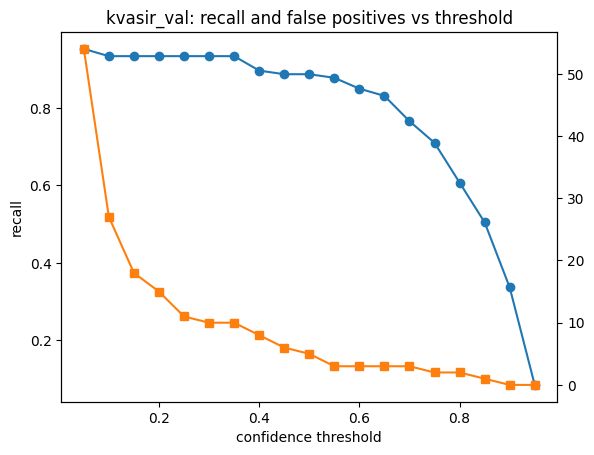

recall at 0.5: 0.888 | at 0.25: 0.935 | at 0.05: 0.953


In [9]:
# Recall vs confidence threshold on the validation split, straight from the cache (report figure 2.2)
import sys, json, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "src/data"); sys.path.insert(0, "src/eval")
import common, metrics
cache = json.load(open("runs/detections/kvasir_val.json"))["images"]
ths = np.linspace(0.05, 0.95, 19); recalls, fps = [], []
for th in ths:
    tp = fp = fn = 0
    for image_id, e in cache.items():
        gt = common.mask_to_boxes(common.load_binary_mask(f"data/processed/kvasir/masks/val/{image_id}.png"))
        pred = [tuple(b[:4]) for b in sorted(e["boxes"], key=lambda b: -b[4]) if b[4] >= th]
        a, b, c = metrics.match_boxes(pred, gt); tp, fp, fn = tp + a, fp + b, fn + c
    recalls.append(tp / (tp + fn)); fps.append(fp)
plt.plot(ths, recalls, marker="o", label="polyp recall (IoU>=0.5)"); plt.xlabel("confidence threshold"); plt.ylabel("recall")
plt.twinx().plot(ths, fps, marker="s", color="C1", label="false-positive boxes"); plt.title("kvasir_val: recall and false positives vs threshold")
plt.savefig("docs/figures/phase3_recall_vs_threshold.png", dpi=120, bbox_inches="tight"); plt.show()
print("recall at 0.5:", round(recalls[9], 3), "| at 0.25:", round(recalls[4], 3), "| at 0.05:", round(recalls[0], 3))

## 7. Validation grid for CASP (DL-34) — `kvasir_val` only

27 runs from the cache (each ≈ 100 images × a few prompts, about 2 min on a T4). The best setting by mean Dice is written into the
CASP configs and into DL-34 **before** any test run.

Every run below (grid, baseline-on-val, section 8, section 9) goes through `run_saved`: the result folder is copied to
`MyDrive/F26-13/runs_phase3/<name>/<dataset>/` the moment it finishes, and a run whose `summary.json` is already there is
restored instead of recomputed. So a Colab disconnect costs one run (about 2 min), not the whole section, and re-running a
cell after a reconnect only does what is still missing. One line is printed per run so progress is visible (challenge C8).

In [10]:
import itertools, json, os, shutil, subprocess, time, pandas as pd
RUNS_DRIVE = "/content/drive/MyDrive/F26-13/runs_phase3"
KEYS = ("images", "mean_dice", "mean_dice_ci95", "mean_iou", "pooled_dice", "pooled_iou", "images_with_empty_prediction",
        "precision", "recall", "prompts_per_image")

def run_saved(name, dataset, args):
    """run_experiment.py for runs/<name>/<dataset>, unless Drive already holds its summary. Returns (summary, status)."""
    local, saved = f"runs/{name}/{dataset.replace('/', '_')}", f"{RUNS_DRIVE}/{name}/{dataset.replace('/', '_')}"
    if os.path.exists(f"{saved}/summary.json"):
        shutil.copytree(saved, local, dirs_exist_ok=True); status = "restored from Drive"
    else:
        t0 = time.time()
        cmd = f"python src/pipeline/run_experiment.py {args} --dataset {dataset} --name {name}"
        r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        if r.returncode != 0 or not os.path.exists(f"{local}/summary.json"):
            print(r.stdout[-1500:]); print(r.stderr[-4000:]); raise SystemExit(f"run failed: {cmd}")
        shutil.copytree(local, saved, dirs_exist_ok=True); status = f"{time.time() - t0:.0f} s"
    return json.load(open(f"{local}/summary.json")), status

rows = []
combos = list(itertools.product([0.15, 0.25, 0.35], [0.6, 0.7, 0.8], [0.6, 0.7, 0.8]))
for k, (t_low, t_high, s_min) in enumerate(combos, 1):
    tag = f"tl{t_low}_th{t_high}_s{s_min}"
    s, status = run_saved(f"grid/{tag}", "kvasir_val",
                          f"--config configs/experiments/casp.yaml --set t_low={t_low} t_high={t_high} s_min={s_min}")
    rows.append({"t_low": t_low, "t_high": t_high, "s_min": s_min, "mean_dice": s["mean_dice"], "mean_iou": s["mean_iou"],
                 "missed": s["images_with_empty_prediction"], "fp": s["detection_fp"], "prompts_per_image": s["prompts_per_image"]})
    print(f"{k:2d}/27 {tag:22s} mean Dice {s['mean_dice']:.4f}  missed {s['images_with_empty_prediction']:3d}  "
          f"fp {s['detection_fp']:3d}  prompts/img {s['prompts_per_image']:.2f}  ({status})", flush=True)
grid = pd.DataFrame(rows).sort_values(["mean_dice", "fp"], ascending=[False, True])
os.makedirs("docs/tables/phase3", exist_ok=True); grid.to_csv("docs/tables/phase3/casp_val_grid.csv", index=False)
print("\n" + grid.head(10).to_string(index=False))
best = grid.iloc[0]; print("\nchosen:", dict(best[["t_low", "t_high", "s_min"]]), f"val mean Dice {best['mean_dice']:.4f}")

 1/27 tl0.15_th0.6_s0.6      mean Dice 0.8860  missed   0  fp  19  prompts/img 2.14  (restored from Drive)
 2/27 tl0.15_th0.6_s0.7      mean Dice 0.8786  missed   1  fp  19  prompts/img 2.14  (restored from Drive)
 3/27 tl0.15_th0.6_s0.8      mean Dice 0.8786  missed   1  fp  19  prompts/img 2.14  (restored from Drive)
 4/27 tl0.15_th0.7_s0.6      mean Dice 0.8829  missed   0  fp  19  prompts/img 2.50  (restored from Drive)
 5/27 tl0.15_th0.7_s0.7      mean Dice 0.8756  missed   1  fp  19  prompts/img 2.50  (restored from Drive)
 6/27 tl0.15_th0.7_s0.8      mean Dice 0.8756  missed   1  fp  19  prompts/img 2.50  (restored from Drive)
 7/27 tl0.15_th0.8_s0.6      mean Dice 0.8810  missed   0  fp  18  prompts/img 3.22  (restored from Drive)
 8/27 tl0.15_th0.8_s0.7      mean Dice 0.8737  missed   1  fp  18  prompts/img 3.22  (restored from Drive)
 9/27 tl0.15_th0.8_s0.8      mean Dice 0.8737  missed   1  fp  18  prompts/img 3.22  (restored from Drive)
10/27 tl0.25_th0.6_s0.6      mean Dic

In [11]:
# Baseline on the validation split for reference (same images as the grid)
s, status = run_saved("grid/baseline", "kvasir_val", "--config configs/experiments/baseline.yaml")
print(f"baseline on kvasir_val ({status}):"); print(json.dumps({k: s[k] for k in KEYS}, indent=2))

baseline on kvasir_val (restored from Drive):
{
  "images": 100,
  "mean_dice": 0.866132,
  "mean_dice_ci95": [
    0.8185266000000002,
    0.9065130499999998
  ],
  "mean_iou": 0.8122070000000001,
  "pooled_dice": 0.8811261455198881,
  "pooled_iou": 0.7875116055234894,
  "images_with_empty_prediction": 4,
  "precision": 0.95,
  "recall": 0.8878504672897196,
  "prompts_per_image": 1.0
}


## 8. Experiments on the test sets (DL-35)

The six runs B, T, C, C-all, C-noiter and O on Kvasir-SEG test and CVC-ClinicDB, with the thresholds chosen in section 7 (t_low = 0.25, t_high = 0.6, s_min = 0.6, also written in `configs/experiments/`). The second cell runs B and C on the nine corrupted settings.

In [13]:
T_LOW, T_HIGH, S_MIN = float(best["t_low"]), float(best["t_high"]), float(best["s_min"])   # from section 7
RUNS = {
    "baseline":       "--config configs/experiments/baseline.yaml --save-masks",
    "threshold_only": f"--config configs/experiments/threshold_only.yaml --set t_low={T_LOW} t_high={T_LOW}",
    "casp":           f"--config configs/experiments/casp.yaml --set t_low={T_LOW} t_high={T_HIGH} s_min={S_MIN} --save-masks",
    "casp_all":       f"--config configs/experiments/casp_all.yaml --set t_low={T_LOW} t_high={T_HIGH} s_min={S_MIN}",
    "casp_noiter":    f"--config configs/experiments/casp_noiter.yaml --set t_low={T_LOW} t_high={T_HIGH} s_min={S_MIN}",
    "oracle":         "--config configs/experiments/oracle.yaml",
}
for ds in ["kvasir_test", "clinicdb"]:
    for name, args in RUNS.items():
        s, status = run_saved(name, ds, args)
        print(f"\n==== {name} on {ds} ({status})"); print(json.dumps({k: s[k] for k in KEYS}, indent=2), flush=True)


==== baseline on kvasir_test (restored from Drive)
{
  "images": 200,
  "mean_dice": 0.8306965,
  "mean_dice_ci95": [
    0.7921221,
    0.8705392125
  ],
  "mean_iou": 0.779623,
  "pooled_dice": 0.8779833357245714,
  "pooled_iou": 0.7825047200092631,
  "images_with_empty_prediction": 18,
  "precision": 0.8774509803921569,
  "recall": 0.8647342995169082,
  "prompts_per_image": 1.02
}

==== threshold_only on kvasir_test (restored from Drive)
{
  "images": 200,
  "mean_dice": 0.8931479999999999,
  "mean_dice_ci95": [
    0.870913025,
    0.9129906499999999
  ],
  "mean_iou": 0.832173,
  "pooled_dice": 0.9012270160698953,
  "pooled_iou": 0.8202122087552386,
  "images_with_empty_prediction": 1,
  "precision": 0.8065843621399177,
  "recall": 0.9468599033816425,
  "prompts_per_image": 1.215
}

==== casp on kvasir_test (restored from Drive)
{
  "images": 200,
  "mean_dice": 0.8914330000000001,
  "mean_dice_ci95": [
    0.8677785250000001,
    0.9120164
  ],
  "mean_iou": 0.8309814999999999,


In [17]:
# Corrupted Kvasir test set: B and C only, if time remains (DL-35). Detection caches are also kept in Drive.
for setting in ["blur_s1", "blur_s2", "blur_s3", "brightness_contrast_s1", "brightness_contrast_s2", "brightness_contrast_s3", "noise_s1", "noise_s2", "noise_s3"]:
    cache = f"kvasir_corrupted_{setting}.json"
    if os.path.exists(f"{DET_DIR}/{cache}"):
        shutil.copy(f"{DET_DIR}/{cache}", "runs/detections/")
    else:
        !python src/pipeline/detect.py --weights {BEST} --dataset kvasir_corrupted/{setting} > /dev/null
        shutil.copy(f"runs/detections/{cache}", DET_DIR)
    for name, args in [("baseline", "--config configs/experiments/baseline.yaml"),
                       ("casp", f"--config configs/experiments/casp.yaml --set t_low={T_LOW} t_high={T_HIGH} s_min={S_MIN}")]:
        s, status = run_saved(name, f"kvasir_corrupted/{setting}", args)
        print(f"{setting:24s} {name:9s} mean Dice {s['mean_dice']:.4f}  missed {s['images_with_empty_prediction']:3d}  ({status})", flush=True)

blur_s1                  baseline  mean Dice 0.8420  missed  15  (restored from Drive)
blur_s1                  casp      mean Dice 0.8700  missed   5  (restored from Drive)
blur_s2                  baseline  mean Dice 0.8107  missed  21  (restored from Drive)
blur_s2                  casp      mean Dice 0.8460  missed   8  (restored from Drive)
blur_s3                  baseline  mean Dice 0.7236  missed  37  (restored from Drive)
blur_s3                  casp      mean Dice 0.8057  missed  11  (restored from Drive)
brightness_contrast_s1   baseline  mean Dice 0.8371  missed  17  (restored from Drive)
brightness_contrast_s1   casp      mean Dice 0.8832  missed   3  (restored from Drive)
brightness_contrast_s2   baseline  mean Dice 0.8343  missed  16  (restored from Drive)
brightness_contrast_s2   casp      mean Dice 0.8846  missed   3  (restored from Drive)
brightness_contrast_s3   baseline  mean Dice 0.7987  missed  25  (restored from Drive)
brightness_contrast_s3   casp      mean Dic

## 9. Tables and Drive backup

In [18]:
!python src/eval/summarize.py
R = "/content/drive/MyDrive/F26-13/runs_phase3"
!mkdir -p {R}
!rsync -a --exclude 'masks' runs/ {R}/            # every per_image.csv, detections.jsonl, summary.json
!rsync -a runs/casp/kvasir_test/masks {R}/casp_kvasir_test_masks/ 2>/dev/null; rsync -a runs/baseline/kvasir_test/masks {R}/baseline_kvasir_test_masks/ 2>/dev/null
!cp docs/figures/phase3_*.png /content/drive/MyDrive/F26-13/figures/ 2>/dev/null
!ls {R}

| Experiment | Dataset | N | Dice (mean, 95% CI) | IoU (mean) | Dice (pooled) | IoU (pooled) | Missed | Prec. | Recall | Prompts/img |
|---|---|---|---|---|---|---|---|---|---|---|
| baseline | clinicdb | 612 | 0.677 [0.648, 0.710] | 0.628 | 0.755 | 0.606 | 144 | 0.890 | 0.686 | 0.8 |
| baseline | kvasir_corrupted_blur_s1 | 200 | 0.842 [0.805, 0.880] | 0.788 | 0.884 | 0.792 | 15 | 0.888 | 0.884 | 1.0 |
| baseline | kvasir_corrupted_blur_s2 | 200 | 0.811 [0.768, 0.854] | 0.757 | 0.870 | 0.770 | 21 | 0.907 | 0.845 | 1.0 |
| baseline | kvasir_corrupted_blur_s3 | 200 | 0.724 [0.671, 0.776] | 0.670 | 0.805 | 0.674 | 37 | 0.882 | 0.758 | 0.9 |
| baseline | kvasir_corrupted_brightness_contrast_s1 | 200 | 0.837 [0.798, 0.875] | 0.784 | 0.881 | 0.787 | 17 | 0.900 | 0.870 | 1.0 |
| baseline | kvasir_corrupted_brightness_contrast_s2 | 200 | 0.834 [0.796, 0.870] | 0.780 | 0.876 | 0.780 | 16 | 0.890 | 0.865 | 1.0 |
| baseline | kvasir_corrupted_brightness_contrast_s3 | 200 | 0.799 [0.754, 0.841] | 

## 10. Results used in the report

The main table (report §5), the paired comparisons on the same images, and the figures. Everything is read from the files written above.

In [19]:
import pandas as pd
r = pd.read_csv("docs/tables/phase3/results.csv")
names = {"baseline": "B baseline", "threshold_only": "T threshold only", "casp": "C CASP v1",
         "casp_all": "C-all", "casp_noiter": "C-noiter", "oracle": "O oracle"}
main = r[r.dataset.isin(["kvasir_test", "clinicdb"])].copy()
main["run"] = main.experiment.map(names)
main["dice [95% CI]"] = main.apply(lambda x: f"{x.mean_dice:.3f} [{x.dice_ci_low:.3f}, {x.dice_ci_high:.3f}]", axis=1)
main["box P / R"] = main.apply(lambda x: f"{x.precision:.3f} / {x.recall:.3f}", axis=1)
main = main.rename(columns={"pooled_dice": "pooled", "images_with_empty_prediction": "missed"})
order = list(names.values())
for ds in ["kvasir_test", "clinicdb"]:
    t = main[main.dataset == ds].set_index("run").loc[order, ["dice [95% CI]", "mean_iou", "pooled", "missed", "box P / R", "prompts_per_image"]]
    print(ds); display(t.round(3))

kvasir_test


,dice [95% CI],mean_iou,pooled,missed,box P / R,prompts_per_image
run,,,,,,
B baseline,"0.831 [0.792, 0.871]",0.780,0.878,18,0.877 / 0.865,1.02
T threshold only,"0.893 [0.871, 0.913]",0.832,0.901,1,0.807 / 0.947,1.22
C CASP v1,"0.891 [0.868, 0.912]",0.831,0.894,1,0.802 / 0.942,2.42
C-all,"0.885 [0.860, 0.907]",0.824,0.879,1,0.802 / 0.942,6.08
C-noiter,"0.892 [0.869, 0.913]",0.832,0.895,1,0.807 / 0.947,2.12
O oracle,"0.952 [0.943, 0.958]",0.912,0.951,0,1.000 / 1.000,1.03


clinicdb


,dice [95% CI],mean_iou,pooled,missed,box P / R,prompts_per_image
run,,,,,,
B baseline,"0.677 [0.648, 0.710]",0.628,0.755,144,0.890 / 0.686,0.81
T threshold only,"0.759 [0.736, 0.785]",0.698,0.799,75,0.820 / 0.780,1.00
C CASP v1,"0.757 [0.734, 0.783]",0.695,0.795,75,0.815 / 0.775,2.18
C-all,"0.757 [0.734, 0.784]",0.696,0.794,75,0.808 / 0.769,5.02
C-noiter,"0.757 [0.734, 0.783]",0.695,0.795,75,0.813 / 0.774,1.89
O oracle,"0.945 [0.942, 0.948]",0.899,0.945,0,1.000 / 1.000,1.06


In [20]:
import sys
sys.path.insert(0, "src/eval"); sys.path.insert(0, "src/data")
import metrics

def per_image(run, ds):
    return pd.read_csv(f"runs/{run}/{ds}/per_image.csv", dtype={"image_id": str}).set_index("image_id")

pairs = [("casp", "baseline", "C - B"), ("threshold_only", "baseline", "T - B"), ("casp", "threshold_only", "C - T"),
         ("casp", "casp_noiter", "C - C-noiter"), ("casp_all", "casp", "C-all - C")]
rows = []
for a, b, label in pairs:
    row = {"comparison": label}
    for ds in ["kvasir_test", "clinicdb"]:
        d = per_image(a, ds).dice - per_image(b, ds).dice
        lo, hi = metrics.bootstrap_ci(d.values, n_resamples=2000)
        row[ds] = f"{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}], {(d > 1e-4).sum()} / {(d < -1e-4).sum()} / {(d.abs() <= 1e-4).sum()}"
    rows.append(row)
pd.DataFrame(rows).set_index("comparison")

,kvasir_test,clinicdb
comparison,,
C - B,"+0.061 [+0.032, +0.090], 27 / 8 / 165","+0.080 [+0.060, +0.100], 100 / 28 / 484"
T - B,"+0.062 [+0.033, +0.092], 22 / 4 / 174","+0.082 [+0.062, +0.102], 93 / 10 / 509"
C - T,"-0.002 [-0.006, +0.002], 13 / 14 / 173","-0.002 [-0.004, +0.000], 39 / 60 / 513"
C - C-noiter,"-0.001 [-0.001, +0.000], 8 / 12 / 180","-0.000 [-0.001, +0.001], 22 / 38 / 552"
C-all - C,"-0.006 [-0.018, +0.001], 16 / 40 / 144","+0.000 [-0.002, +0.002], 68 / 69 / 475"


In [21]:
corr = r[r.dataset.str.startswith("kvasir_corrupted") | (r.dataset == "kvasir_test")]
corr = corr[corr.experiment.isin(["baseline", "casp"])]
corr = corr.pivot(index="dataset", columns="experiment", values=["mean_dice", "images_with_empty_prediction"])
corr.columns = ["B dice", "C dice", "B missed", "C missed"]
corr["C - B"] = corr["C dice"] - corr["B dice"]
corr.index = corr.index.str.replace("kvasir_corrupted_", "").str.replace("kvasir_test", "clean")
corr.round(3)

,B dice,C dice,B missed,C missed,C - B
dataset,,,,,
blur_s1,0.842,0.870,15.0,5.0,0.028
blur_s2,0.811,0.846,21.0,8.0,0.035
blur_s3,0.724,0.806,37.0,11.0,0.082
brightness_contrast_s1,0.837,0.883,17.0,3.0,0.046
brightness_contrast_s2,0.834,0.885,16.0,3.0,0.050
brightness_contrast_s3,0.799,0.838,25.0,12.0,0.040
noise_s1,0.800,0.875,20.0,2.0,0.075
noise_s2,0.687,0.761,40.0,23.0,0.074
noise_s3,0.016,0.035,196.0,192.0,0.019


phase3_yolo_training_curves.png


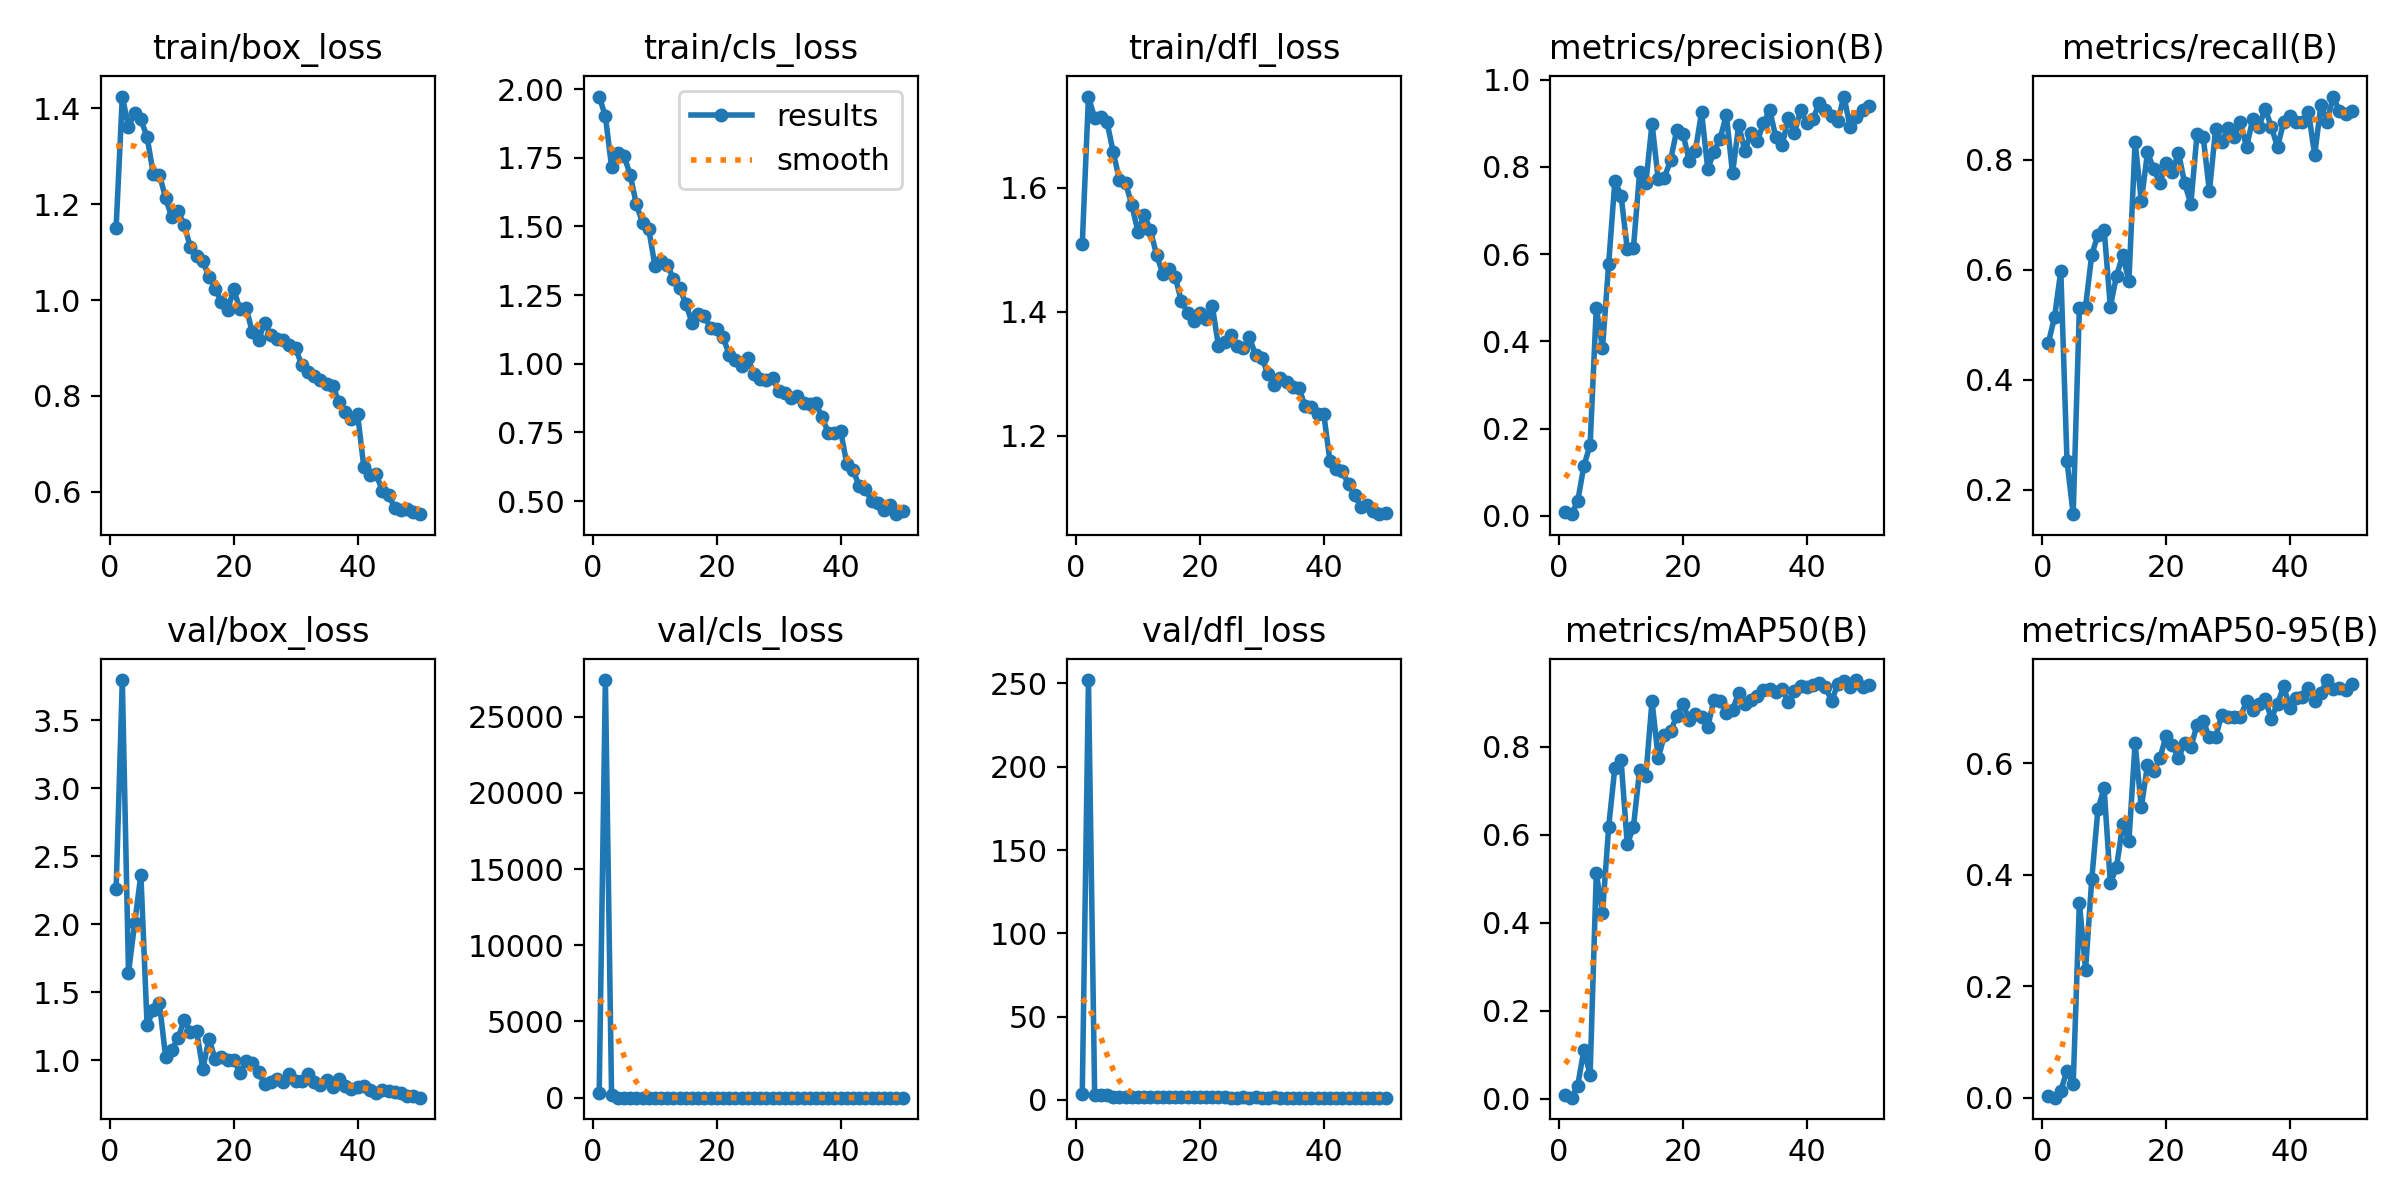

phase3_recall_vs_threshold.png


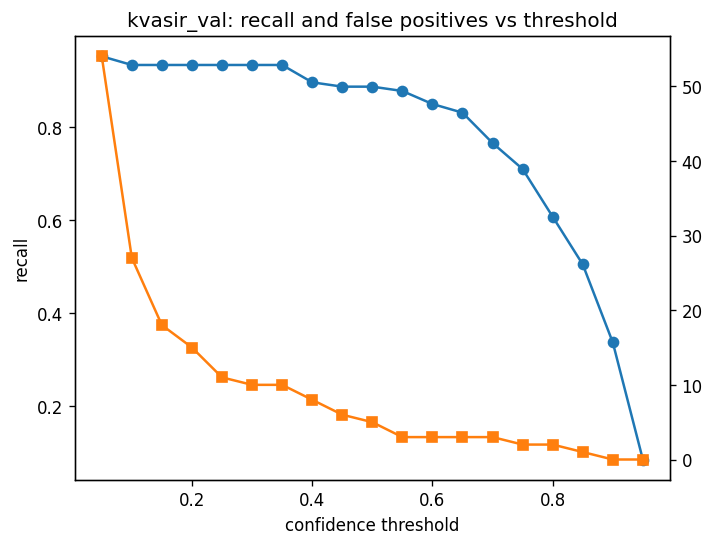

phase3_examples_kvasir_test.png


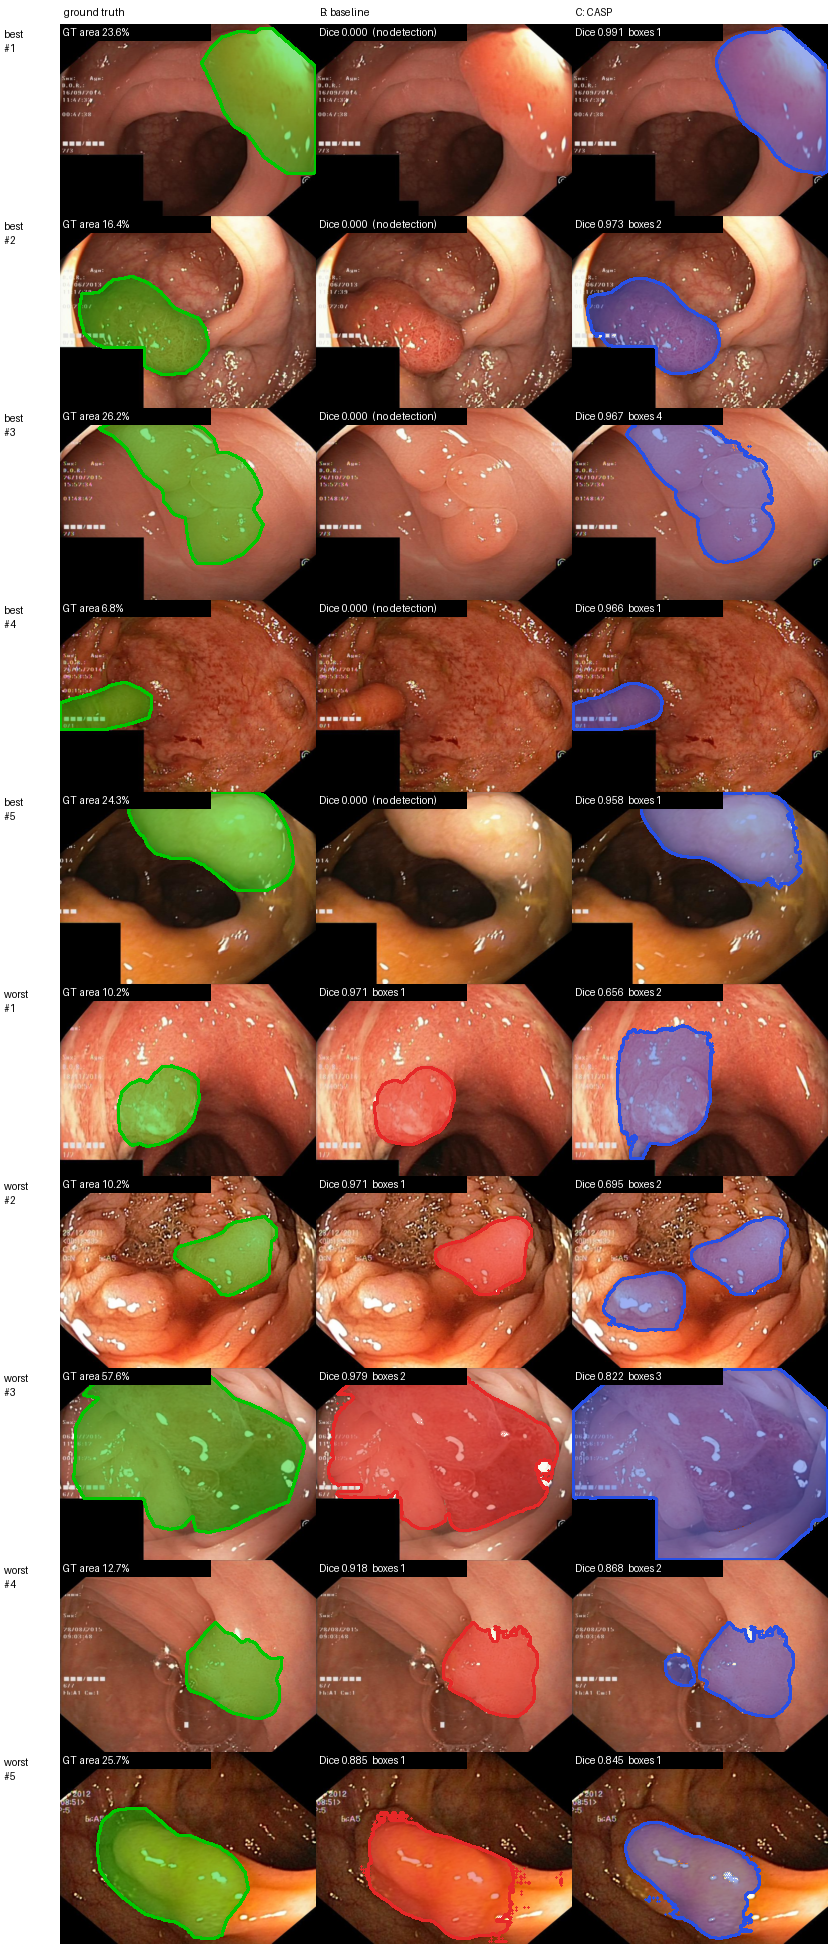

phase3_corrupted_dice.png


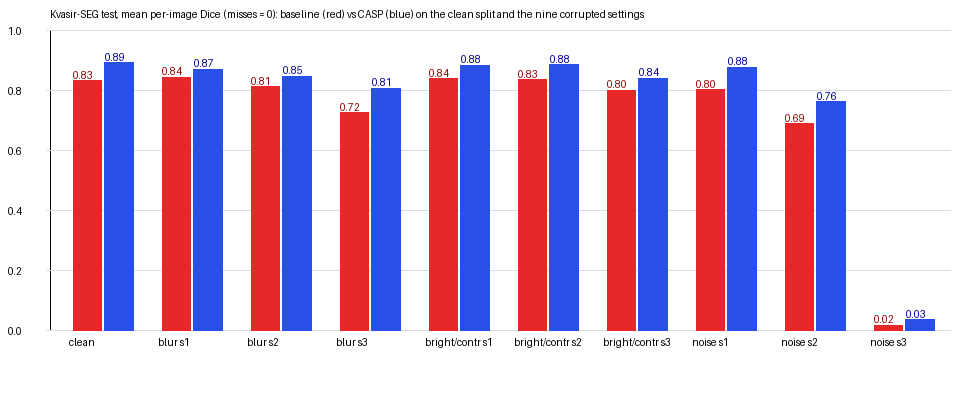

In [22]:
from IPython.display import Image, display
for f in ["phase3_yolo_training_curves.png", "phase3_recall_vs_threshold.png",
          "phase3_examples_kvasir_test.png", "phase3_corrupted_dice.png"]:
    print(f); display(Image(filename=f"docs/figures/{f}", width=800))